# RoadSense AI: Multi-Task Machine Learning for Road Accident Severity
## Notebook 04: Task B — 3-Class Severity Classification (Fatal vs Serious vs Slight)
**Course Module**: Artificial Intelligence (CO5: Classification, Regression and Prediction Problems)
**Lead Team Member**: Member 3 (Multi-Class & Extreme Imbalance Specialist)

---

### Objectives & Rigorous Protocol:
1. **3-Class Formulation**: Predict exact severity level — `Fatal` (0, ~1.48%), `Serious` (1, ~21.86%), or `Slight` (2, ~76.66%).
2. **The Extreme Imbalance Challenge**: Unweighted baselines predict 0% Fatal recall. We compare Class Weights vs SMOTE vs Random Undersampling across 5 model architectures.
3. **One-vs-Rest (OvR) Fatal Decision Rule**: Standard argmax prediction suppresses the rare Fatal class. We apply an OvR threshold $\tau_{\text{fatal}}^*$ maximizing $F_2$ for the Fatal class on 2022 validation.
4. **Platt Probability Recalibration**: Recalibrate Fatal predicted probabilities on the validation fold.
5. **Validation-Only Selection**: Model selection is governed exclusively by 2022 validation metrics.
6. **Complete Reporting**: Report per-class precision, recall, and F1 for all three classes, plus the full 3x3 confusion matrix on 2023 holdout test.

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Ensure project root is accessible
sys.path.append(os.path.abspath('..'))
from src.features import ALL_MODEL_FEATURES
from src.evaluate import evaluate_multiclass_classification

print('Environment and libraries initialized.')

Environment and libraries initialized.


## 1. Load Clean Dataset & Inspect 3-Class Severe Imbalance
We inspect the distribution across Fatal (0), Serious (1), and Slight (2).

In [2]:
df = pd.read_parquet('../data/clean_roadsense.parquet')
counts = df['target_severity_3class'].value_counts().sort_index()
props = (df['target_severity_3class'].value_counts(normalize=True).sort_index() * 100).round(2)
labels = ['0: Fatal', '1: Serious', '2: Slight']
display(pd.DataFrame({'Severity Class': labels, 'Count': counts.values, 'Percentage (%)': props.values}))

,Severity Class,Count,Percentage (%)
0,0: Fatal,4598,1.48
1,1: Serious,68055,21.86
2,2: Slight,238696,76.67


## 2. Validation Comparison Across 15 Configurations
We load the 2022 validation results table (`outputs/tables/task_b_validation_comparison.csv`).
Notice the dramatic improvement in Fatal recall when using OvR $F_2$ thresholding compared to standard argmax baselines.

In [3]:
val_b_table = pd.read_csv('../outputs/tables/task_b_validation_comparison.csv')
print('Top 5 Task B Configurations Ranked by Validation Macro-F1:')
display(val_b_table.sort_values(by='macro_f1', ascending=False).head(5)[[
    'model', 'imbalance_strategy', 'train_time_sec', 'optimal_fatal_threshold', 
    'fatal_f2_score', 'macro_f1', 'fatal_recall', 'fatal_precision', 'fatal_f1', 
    'serious_recall', 'slight_recall', 'roc_auc_ovr', 'leakage_warning'
]])

Top 5 Task B Configurations Ranked by Validation Macro-F1:


,model,imbalance_strategy,train_time_sec,optimal_fatal_threshold,fatal_f2_score,macro_f1,fatal_recall,fatal_precision,fatal_f1,serious_recall,slight_recall,roc_auc_ovr,leakage_warning
3,Random Forest,Class_Weights,3.63,0.040,0.2015,0.4007,0.4007,0.0677,0.1159,0.4863,0.6163,0.6871,PASSED (<=0.90)
6,LightGBM,Class_Weights,2.69,0.040,0.2094,0.4002,0.4220,0.0686,0.1180,0.5011,0.6030,0.6987,PASSED (<=0.90)
4,Random Forest,SMOTE,15.22,0.035,0.1945,0.3982,0.4095,0.0627,0.1088,0.2553,0.7803,0.6891,PASSED (<=0.90)
5,Random Forest,Random_Undersampling,1.26,0.045,0.1979,0.3954,0.3627,0.0702,0.1176,0.4982,0.6004,0.6739,PASSED (<=0.90)
12,Small MLP,Class_Weights,8.95,0.040,0.2038,0.3953,0.3889,0.0705,0.1193,0.5539,0.5650,0.6809,PASSED (<=0.90)


## 3. Fatal Class Probability Recalibration Curve
We inspect the calibration curve for the Fatal class before and after Platt recalibration.

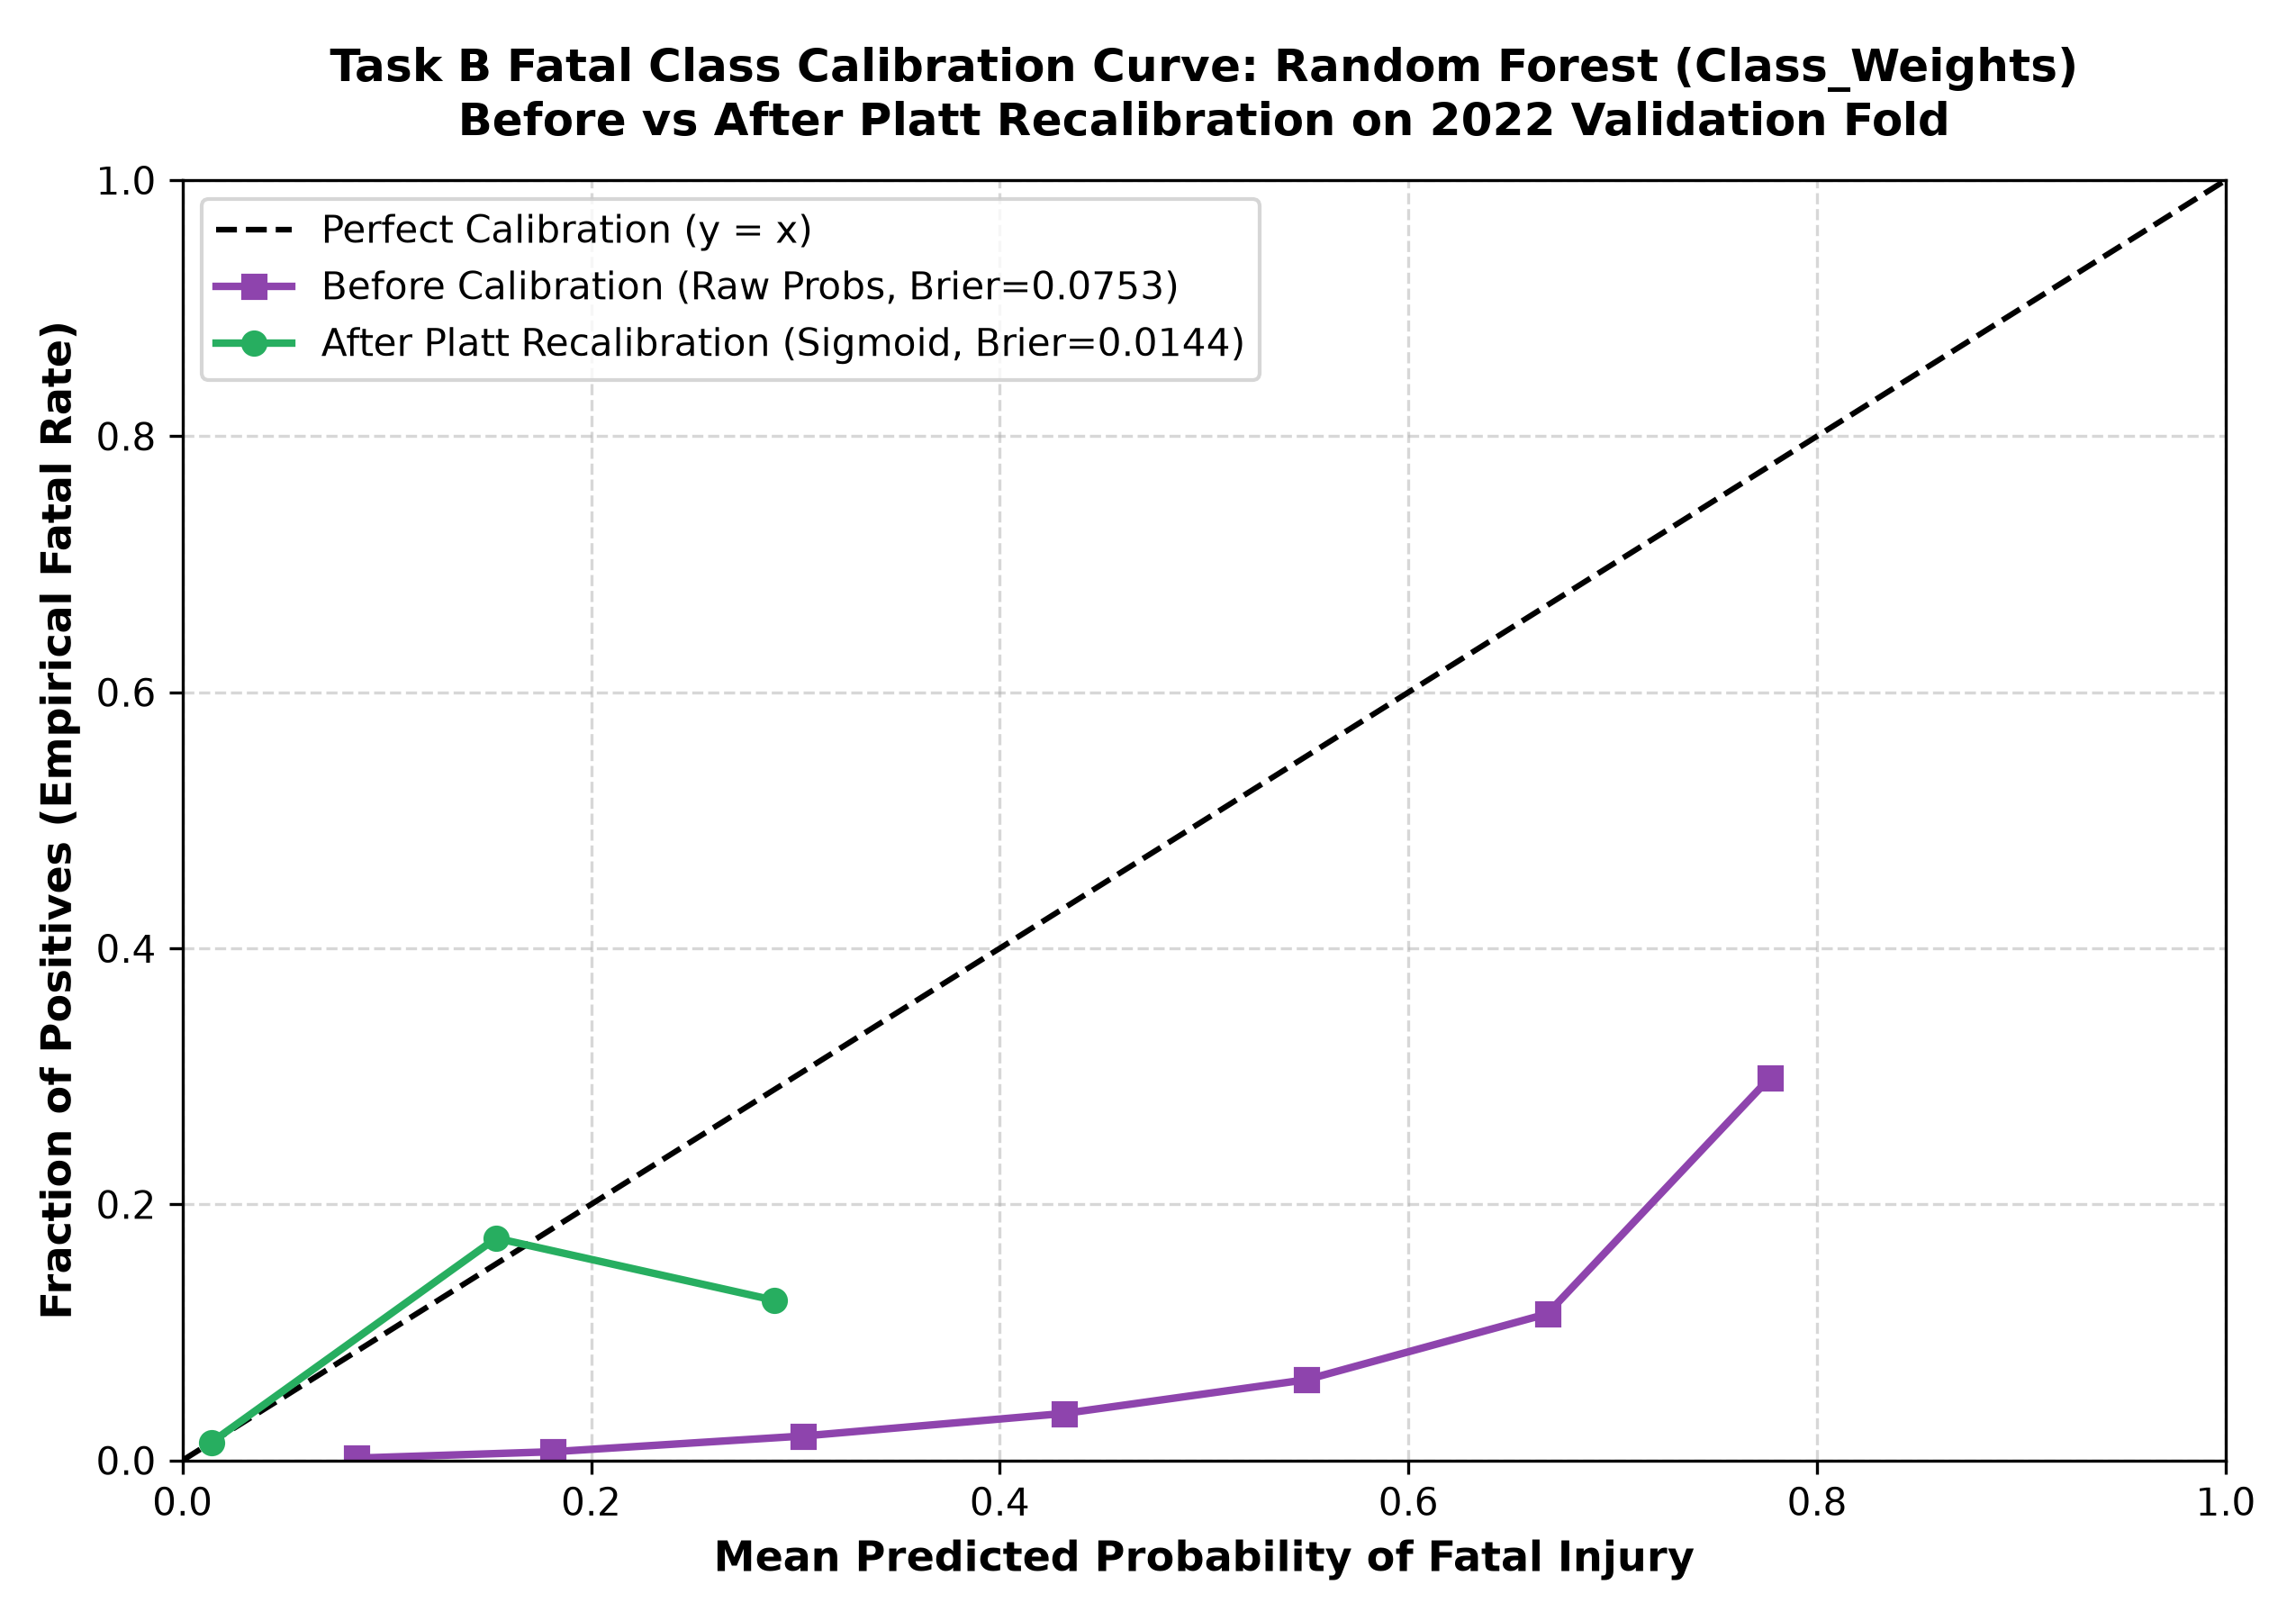

In [4]:
display(Image(filename='../outputs/charts/10_calibration_curve_task_b.png', width=750))

## 4. Winning Model Artifact & 2023 Holdout Test Evaluation
We evaluate the winning model on the 2023 holdout test set with complete per-class metrics and confusion matrix.

In [5]:
model_b_artifact = joblib.load('../models/best_model_task_b.joblib')
print(f'Winning Model: {model_b_artifact["model_name"]} ({model_b_artifact["imbalance_strategy"]})')
print(f'Optimal Fatal OvR Threshold: {model_b_artifact["optimal_fatal_threshold"]}')
print(f'Tuned Hyperparameters: {model_b_artifact["hyperparameters"]}')

test_df = df[df['collision_year'] == 2023]
X_test = test_df[ALL_MODEL_FEATURES]
y_test = test_df['target_severity_3class'].values

test_probs = model_b_artifact['pipeline'].predict_proba(X_test)
raw_fatal = test_probs[:, 0]
calib_fatal = model_b_artifact['fatal_calibrator'].predict_proba(raw_fatal)

opt_fatal_t = model_b_artifact['optimal_fatal_threshold']
test_preds = []
for i in range(len(test_probs)):
    if calib_fatal[i] >= opt_fatal_t:
        test_preds.append(0)
    else:
        if test_probs[i, 1] >= test_probs[i, 2]:
            test_preds.append(1)
        else:
            test_preds.append(2)
test_preds = np.array(test_preds)

test_metrics_b = evaluate_multiclass_classification(y_test, test_preds, test_probs)

print('\n--- 2023 Holdout Test Per-Class Performance ---')
per_class_summary = pd.DataFrame({
    'Class': ['Fatal (0)', 'Serious (1)', 'Slight (2)'],
    'Precision': [test_metrics_b['fatal_precision'], test_metrics_b['serious_precision'], test_metrics_b['slight_precision']],
    'Recall': [test_metrics_b['fatal_recall'], test_metrics_b['serious_recall'], test_metrics_b['slight_recall']],
    'F1-Score': [test_metrics_b['fatal_f1'], test_metrics_b['serious_f1'], test_metrics_b['slight_f1']]
})
display(per_class_summary)

print(f'Macro-F1: {test_metrics_b["macro_f1"]:.4f} | Overall Accuracy: {test_metrics_b["accuracy"]:.4f} | OVR ROC-AUC: {test_metrics_b["roc_auc_ovr"]:.4f}')

print('\n--- 2023 Holdout Test 3x3 Confusion Matrix ---')
cm = np.array(test_metrics_b['confusion_matrix'])
cm_df = pd.DataFrame(cm, index=['Actual Fatal', 'Actual Serious', 'Actual Slight'], columns=['Pred Fatal', 'Pred Serious', 'Pred Slight'])
display(cm_df)

Winning Model: Random Forest (Class_Weights)
Optimal Fatal OvR Threshold: 0.04
Tuned Hyperparameters: {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 10}



--- 2023 Holdout Test Per-Class Performance ---


,Class,Precision,Recall,F1-Score
0,Fatal (0),0.0601,0.4494,0.1060
1,Serious (1),0.3144,0.4756,0.3785
2,Slight (2),0.8476,0.6138,0.7120


Macro-F1: 0.3988 | Overall Accuracy: 0.5803 | OVR ROC-AUC: 0.6878

--- 2023 Holdout Test 3x3 Confusion Matrix ---


,Pred Fatal,Pred Serious,Pred Slight
Actual Fatal,684,525,313
Actual Serious,3857,11146,8435
Actual Slight,6843,23784,48671


## 5. Post-Selection Reference Table (All 15 Models on 2023 Test)
All 15 model configurations evaluated on 2023 test as post-selection reference.

In [6]:
ref_b_table = pd.read_csv('../outputs/tables/task_b_post_selection_reference.csv')
display(ref_b_table[[
    'model', 'imbalance_strategy', 'applied_fatal_threshold', 'train_time_sec',
    'macro_f1', 'fatal_recall', 'fatal_precision', 'fatal_f1',
    'serious_recall', 'slight_recall', 'roc_auc_ovr', 'leakage_warning'
]].sort_values(by='macro_f1', ascending=False))

,model,imbalance_strategy,applied_fatal_threshold,train_time_sec,macro_f1,fatal_recall,fatal_precision,fatal_f1,serious_recall,slight_recall,roc_auc_ovr,leakage_warning
6,LightGBM,Class_Weights,0.040,2.69,0.4027,0.3929,0.0626,0.1080,0.5026,0.6140,0.6946,PASSED (<=0.90)
3,Random Forest,Class_Weights,0.040,3.63,0.4026,0.3922,0.0632,0.1089,0.4846,0.6243,0.6855,PASSED (<=0.90)
9,XGBoost,Class_Weights,0.035,4.62,0.3974,0.4363,0.0590,0.1040,0.4856,0.6065,0.6967,PASSED (<=0.90)
4,Random Forest,SMOTE,0.035,15.22,0.3964,0.3844,0.0580,0.1009,0.2467,0.7910,0.6876,PASSED (<=0.90)
5,Random Forest,Random_Undersampling,0.045,1.26,0.3960,0.3489,0.0636,0.1076,0.4994,0.6056,0.6729,PASSED (<=0.90)
12,Small MLP,Class_Weights,0.040,8.95,0.3957,0.3679,0.0639,0.1088,0.5466,0.5748,0.6762,PASSED (<=0.90)
11,XGBoost,Random_Undersampling,0.040,1.53,0.3931,0.3758,0.0617,0.1059,0.4907,0.6007,0.6815,PASSED (<=0.90)
8,LightGBM,Random_Undersampling,0.035,1.80,0.3871,0.4120,0.0583,0.1022,0.4647,0.5981,0.6758,PASSED (<=0.90)
14,Small MLP,Random_Undersampling,0.035,1.49,0.3855,0.4034,0.0549,0.0966,0.4406,0.6116,0.6697,PASSED (<=0.90)
1,Decision Tree,SMOTE,0.030,8.01,0.3827,0.4034,0.0518,0.0918,0.4003,0.6321,0.6557,PASSED (<=0.90)
